# Extension A: Hydrogen n = 2 (2s and 2p together, with the Lamb shift)

**Goal.** Put two different orbital levels, 2s and 2p, into one Hamiltonian, add the Lamb shift, and see
what a magnetic field does to the whole $n=2$ manifold. We then compare a predicted level-crossing field
with the literature.

**The eight states.** 2S$_{1/2}$ (2 states), 2P$_{1/2}$ (2 states), 2P$_{3/2}$ (4 states).

**Model.** Spin-orbit and Zeeman terms both conserve $l$, so the 8x8 Hamiltonian is two blocks:
$H = H(l{=}0) \oplus H(l{=}1)$. Two numbers come from experiment: the 2P fine-structure interval
(sets $\zeta$) and the **Lamb shift**, the small QED energy by which 2S$_{1/2}$ lies above 2P$_{1/2}$.
Ordinary quantum mechanics with the Dirac equation says they should be degenerate.

In [1]:
import sys
sys.path.insert(0, '..')          # so `import src...` works from the notebooks folder
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
import pandas as pd
from src.hydrogen import (track_n2, level_index, ev_to_mhz, mhz_to_ev, h_n2, label_states,
                          LAMB_SHIFT_MHZ, FINE_2P_MHZ, dirac_fine_structure_mhz)
from src.solvers import find_crossings
from src.constants import MU_B_EV, G_S
from src.hamiltonians import landé_g

b, e, labels, vectors = track_n2(np.linspace(1e-6, 0.5, 2500))     # tesla, eV, labels, eigenvectors

zero = labels.assign(energy_MHz=ev_to_mhz(e[0]))
print('Zero-field level scheme (energies above 2P1/2, in MHz):')
print(zero[['term', 'mj', 'energy_MHz']].round(2).to_string(index=False))

Zero-field level scheme (energies above 2P1/2, in MHz):
 term   mj  energy_MHz
2P1/2 -0.5       -0.00
2P1/2  0.5        0.00
2S1/2 -0.5     1057.85
2S1/2  0.5     1057.88
2P3/2 -1.5    10969.01
2P3/2 -0.5    10969.03
2P3/2  0.5    10969.05
2P3/2  1.5    10969.07


The scheme is exactly what the inputs say: 2P$_{1/2}$ at 0, 2S$_{1/2}$ at the Lamb shift (1058 MHz),
2P$_{3/2}$ at the fine-structure interval (10969 MHz). The labels (term and $m_j$) were read off the
eigenvectors, not typed in.

**Cross-check of one input.** Pure Dirac theory predicts the 2P interval as $\alpha^2 \mathrm{Ry}/16$:

In [2]:
print('Dirac theory         : %.1f MHz' % dirac_fine_structure_mhz())
print('value used (measured) : %.1f MHz' % FINE_2P_MHZ)
print('difference            : %.2f %%   (QED corrections)' % (100 * (FINE_2P_MHZ / dirac_fine_structure_mhz() - 1)))

Dirac theory         : 10949.3 MHz
value used (measured) : 10969.0 MHz
difference            : 0.18 %   (QED corrections)


## Weak field: Landé slopes for all three terms

At tiny $B$ every level should move with slope $g_J m_j$ (units of $\mu_B$):

In [3]:
bs, es, lab, _ = track_n2([1e-6, 1e-4, 2e-4])
g = {'2S1/2': landé_g(0, 0.5), '2P1/2': landé_g(1, 0.5), '2P3/2': landé_g(1, 1.5)}
rows = []
for _, r in lab.iterrows():
    slope = (es[2, r.level] - es[1, r.level]) / (MU_B_EV * 1e-4)
    rows.append((r.term, r.mj, slope, g[r.term] * r.mj))
print(pd.DataFrame(rows, columns=['term', 'mj', 'numeric slope', 'g_J * mj']).round(4).sort_values(['term', 'mj']).to_string(index=False))

 term   mj  numeric slope  g_J * mj
2P1/2 -0.5        -0.3330   -0.3329
2P1/2  0.5         0.3329    0.3329
2P3/2 -1.5        -2.0012   -2.0012
2P3/2 -0.5        -0.6670   -0.6671
2P3/2  0.5         0.6671    0.6671
2P3/2  1.5         2.0012    2.0012
2S1/2 -0.5        -1.0012   -1.0012
2S1/2  0.5         1.0012    1.0012


## The full picture

The dotted line marks the crossing of 2S$_{1/2}$($m_j=-\tfrac12$) with 2P$_{1/2}$($m_j=+\tfrac12$).

predicted crossing: 573.4 gauss
literature        : about 570 gauss (arXiv:1104.4421; that paper includes hyperfine structure)


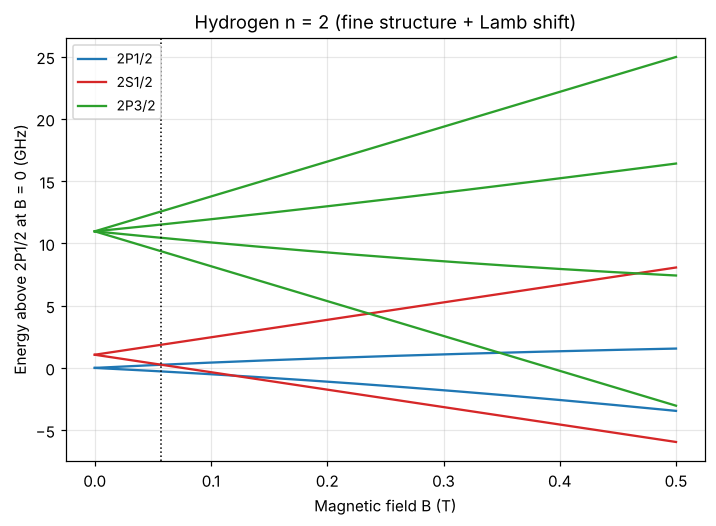

In [4]:
from src.animation import plot_n2_levels
i = level_index(labels, '2S1/2', -0.5)
j = level_index(labels, '2P1/2', +0.5)
b_cross = find_crossings(b, e[:, i], e[:, j])[0]
plot_n2_levels(b, e, labels, mark_fields_gauss=[b_cross * 1e4])
plt.show()
print('predicted crossing: %.1f gauss' % (b_cross * 1e4))
print('literature        : about 570 gauss (arXiv:1104.4421; that paper includes hyperfine structure)')

**Agreement within about 1 %**, with one input (the Lamb shift) and no fitting to this crossing.

A straight-line estimate gives 566.5 G. The exact result is higher because the field also mixes
2P$_{1/2}$ with 2P$_{3/2}$, bending the 2P$_{1/2}$ level down by about 13 MHz at this field.

## The crossing field *measures* the Lamb shift

Because the crossing happens where the two levels meet, its position is set by the Lamb shift.
Scale the Lamb shift by 0.5, 1 and 2 and watch the crossing move:

In [5]:
for scale in (0.5, 1.0, 2.0):
    b2, e2, l2, _ = track_n2(np.linspace(1e-6, 0.3, 1500), lamb_mhz=LAMB_SHIFT_MHZ * scale)
    c = find_crossings(b2, e2[:, level_index(l2, '2S1/2', -0.5)], e2[:, level_index(l2, '2P1/2', 0.5)])
    print('Lamb shift x %.1f = %7.1f MHz  ->  crossing at %6.1f G' % (scale, LAMB_SHIFT_MHZ * scale, c[0] * 1e4))

Lamb shift x 0.5 =   528.9 MHz  ->  crossing at  285.0 G
Lamb shift x 1.0 =  1057.9 MHz  ->  crossing at  573.4 G
Lamb shift x 2.0 =  2115.7 MHz  ->  crossing at 1160.3 G


Doubling the Lamb shift roughly doubles the crossing field. This is why level crossings were used to
measure it.

## Every crossing between 2S and 2P levels below 0.5 T

In [6]:
import itertools
rows = []
for a, c_ in itertools.combinations(range(8), 2):
    la, lc = labels.iloc[a], labels.iloc[c_]
    if la.term == lc.term:
        continue
    for bc in find_crossings(b, e[:, a], e[:, c_]):
        rows.append((bc * 1e4, '%s (mj=%+.1f)' % (la.term, la.mj), '%s (mj=%+.1f)' % (lc.term, lc.mj)))
table = pd.DataFrame(sorted(rows), columns=['B (gauss)', 'level A', 'level B'])
print(table.round(1).head(12).to_string(index=False))
print('... %d crossings in total between different terms' % len(table))

 B (gauss)         level A         level B
     573.4 2P1/2 (mj=+0.5) 2S1/2 (mj=-0.5)
    1194.9 2P1/2 (mj=-0.5) 2S1/2 (mj=-0.5)
    2358.6 2S1/2 (mj=+0.5) 2P3/2 (mj=-1.5)
    3482.5 2P1/2 (mj=+0.5) 2P3/2 (mj=-1.5)
    4661.8 2S1/2 (mj=+0.5) 2P3/2 (mj=-0.5)
... 5 crossings in total between different terms


## Why crossings and not anticrossings?

In the table, levels with the *same* $m_j$ (for example 2S$_{1/2}$ and 2P$_{1/2}$ with $m_j=-\tfrac12$,
crossing near 1195 G) simply cross. In Level 3 same-$m_j$ levels repelled each other, but those were in the *same* $l$ block.
Here the two blocks are different $l$, and a magnetic field never mixes different $l$. We can prove it
from the eigenvectors:

In [7]:
worst = 0.0
for k in range(0, len(b), 20):
    s_weight = label_states(vectors[k]).s_weight.to_numpy()
    worst = max(worst, float(np.max(np.minimum(s_weight, 1 - s_weight))))
print('largest 2s/2p mixing found at any field: %.2e   (0 = never mixes)' % worst)

largest 2s/2p mixing found at any field: 0.00e+00   (0 = never mixes)


**Take-away.** One extra block and one measured number (the Lamb shift) turn the model into a hydrogen
$n=2$ simulator. It reproduces the Landé slopes of all three terms and predicts the 2S-2P crossing field to
within about 1 % of the literature value. Real experiments (Lamb and Retherford) used an *electric* field to mix 2s
with 2p; adding that coupling is a natural next extension.